# Week 1 assignment: Linear regression using Python

# 1. Load and explore the data

In [1]:
# Import all the necessary packages.
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.stats.api as sms
import sklearn
import matplotlib.pyplot as plt

from sklearn import linear_model
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.linear_model import LinearRegression
from statsmodels.formula.api import ols

import warnings  
warnings.filterwarnings('ignore')

In [2]:
# Load the CSV file.

reviews = pd.read_csv('turtle_reviews.csv')

# View the DataFrame.

reviews.head()

,gender,age,remuneration (k£),spending_score (1-100),loyalty_points,education,language,platform,product,review,summary
0,Male,18,12.30,39,210,graduate,EN,Web,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,EN,Web,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,EN,Web,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,EN,Web,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,EN,Web,291,As my review of GF9's previous screens these w...,Money trap


In [3]:
# view the metadata
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   gender                  2000 non-null   object 
 1   age                     2000 non-null   int64  
 2   remuneration (k£)       2000 non-null   float64
 3   spending_score (1-100)  2000 non-null   int64  
 4   loyalty_points          2000 non-null   int64  
 5   education               2000 non-null   object 
 6   language                2000 non-null   object 
 7   platform                2000 non-null   object 
 8   product                 2000 non-null   int64  
 9   review                  2000 non-null   object 
 10  summary                 2000 non-null   object 
dtypes: float64(1), int64(4), object(6)
memory usage: 172.0+ KB


In [4]:
# check for missing values
reviews.isna().sum()

gender                    0
age                       0
remuneration (k£)         0
spending_score (1-100)    0
loyalty_points            0
education                 0
language                  0
platform                  0
product                   0
review                    0
summary                   0
dtype: int64

In [6]:
# Descriptive Statistics
reviews.describe()

,age,remuneration (k£),spending_score (1-100),loyalty_points,product
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,39.495000,48.079060,50.000000,1578.032000,4320.521500
std,13.573212,23.123984,26.094702,1283.239705,3148.938839
min,17.000000,12.300000,1.000000,25.000000,107.000000
25%,29.000000,30.340000,32.000000,772.000000,1589.250000
50%,38.000000,47.150000,50.000000,1276.000000,3624.000000
75%,49.000000,63.960000,73.000000,1751.250000,6654.000000
max,72.000000,112.340000,99.000000,6847.000000,11086.000000


## 2. Drop Columns

In [7]:
# Drop 'language' and 'platform' columns.
reviews = reviews.drop(columns=['language', 'platform'])

# Sense-check.
reviews.head()

,gender,age,remuneration (k£),spending_score (1-100),loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap


## 3. Rename Columns

In [8]:
# Rename columns for easier reference.
reviews.rename(columns={'remuneration (k£)': 'remuneration',
                         'spending_score (1-100)': 'spending_score'},
               inplace=True)

# view column names
reviews.columns

Index(['gender', 'age', 'remuneration', 'spending_score', 'loyalty_points',
       'education', 'product', 'review', 'summary'],
      dtype='object')

## 4. Save the DataFrame as a CSV file

In [11]:
# Save the cleaned DataFrame.
reviews.to_csv('turtle_reviews_clean.csv', index=False)

# Import new CSV and view dataframe.
reviews2 = pd.read_csv('turtle_reviews_clean.csv')
reviews2.head()

,gender,age,remuneration,spending_score,loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap


## 5. Linear Regression

### 5a. Spending vs Loyalty

In [12]:
# Define the dependent variable.
y = reviews2['loyalty_points']

# Define independent variable.
X_spending = reviews2['spending_score']

# Reshape for sklearn.
X = X_spending.values.reshape(-1, 1)

In [13]:
# Create and fit the model.

model_spending = LinearRegression()
model_spending.fit(X, y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [14]:
# Print R squared
print('R-squared:', model_spending.score(X, y))

# Print the intercept value
print('Intercept:', model_spending.intercept_)

# Print the coefficient value
print('Coefficient:', model_spending.coef_)

R-squared: 0.4520008865838909
Intercept: -75.05266293364889
Coefficient: [33.06169326]


- R-squared is 0.452, meaning spending score explains around 45% of the variation in loyalty points. This is a moderate relationship.
- The coefficient is positive (33.06), which matches intuition: customers who spend more accumulate more loyalty points, consistent with typical loyalty scheme design.

In [15]:
# Extract the predicted values.
y_pred_spending = model_spending.predict(X)
print(y_pred_spending)

[1214.35337415 2602.94449102  123.31749662 ... 2933.56142361  453.93442921
  189.44088314]


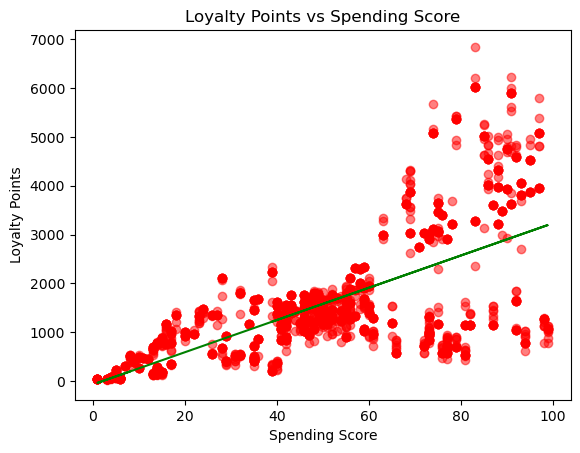

In [16]:
# Plot the graph with a regression line.
plt.scatter(X_spending, y, alpha=0.5, color='red')
plt.plot(X_spending, y_pred_spending, color='green')
plt.xlabel('Spending Score')
plt.ylabel('Loyalty Points')
plt.title('Loyalty Points vs Spending Score')
plt.show()

- The scatter plot does not show one clean, uniform linear cloud. Instead, there appears to be two distinct bands: a lower band of customers (spending score up to around 60) whose loyalty points rise gently and stay under 2,000, and a separate, steeper band of customers (spending score above 60+) whose loyalty points jump sharply higher, several reaching 5,000–7,000.
- This suggests the population may contain at least two different customer segments rather than a single group, and a simple linear model averages across both, which is likely why the fit is only moderate rather than strong.

### 5b. Remuneration vs Loyalty

In [19]:
# Define the dependent variable.
y = reviews2['loyalty_points']

# Define independent variable.
X_remuneration = reviews2['remuneration']

# Reshape for sklearn.
X = X_remuneration.values.reshape(-1, 1)

In [18]:
# Create and fit the model.
model_remuneration = LinearRegression()
model_remuneration.fit(X, y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [20]:
# Print R squared
print('R-squared:', model_remuneration.score(X, y))

# Print the coefficient value
print('Coefficient:', model_remuneration.coef_)

# Print the intercept value
print('Intercept:', model_remuneration.intercept_)

R-squared: 0.3795357732793636
Coefficient: [34.18782549]
Intercept: -65.6865127950191


- R-squared is 0.380: remuneration explains around 38% of the variation in loyalty points, a slightly weaker relationship than spending score.
- The coefficient is positive (34.19), again matching intuition: higher-earning customers tend to accumulate more loyalty points, possibly because higher income supports higher spend.

In [21]:
# Extract the predicted values.
y_pred_remuneration = model_remuneration.predict(X)
print(y_pred_remuneration)

[ 354.82374068  354.82374068  382.85775758 ... 3102.15739671 3298.39551499
 3102.15739671]


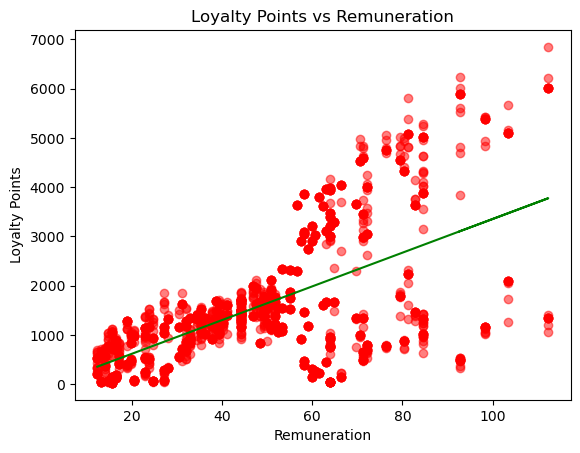

In [22]:
# Plot the graph with a regression line.
plt.scatter(X_remuneration, y, alpha=0.5, color = 'red')
plt.plot(X_remuneration, y_pred_remuneration, color='green')
plt.xlabel('Remuneration')
plt.ylabel('Loyalty Points')
plt.title('Loyalty Points vs Remuneration')
plt.show()

- The scatter shows a positive trend at lower-to-mid remuneration levels, but the spread widens considerably as remuneration increases. At remuneration above 80k£, points range anywhere from under 1,000 to over 6,000 for similar remuneration values. This unevenness means the linear model is a much weaker predictor for higher earners specifically, even though it captures some signal at the lower end.

### 5c. Age vs loyalty

In [23]:
# Define the dependent variable.
y = reviews2['loyalty_points']

# Define independent variable.
X_age = reviews2['age']

# Reshape for sklearn.
X = X_age.values.reshape(-1, 1)

In [24]:
# Create and fit the model.
model_age = LinearRegression()
model_age.fit(X, y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [25]:
# Print R squared
print('R-squared:', model_age.score(X, y))

# Print the intercept value
print('Intercept:', model_age.intercept_)

# Print the coefficient value
print('Coefficient:', model_age.coef_)

R-squared: 0.0018015480437203468
Intercept: 1736.5177393990623
Coefficient: [-4.01280515]


- R-squared is 0.0018, which is essentially zero. Age explains almost none of the variation in loyalty points.
- The coefficient is slightly negative (-4.01), technically suggesting loyalty points decline marginally with age, but given the near-zero R-squared, this coefficient is not meaningfully different from no relationship at all.

In [26]:
# Extract the predicted values.
y_pred_age = model_age.predict(X)
print(y_pred_age)

[1664.2872467  1644.22322095 1648.2360261  ... 1600.0823643  1600.0823643
 1608.1079746 ]


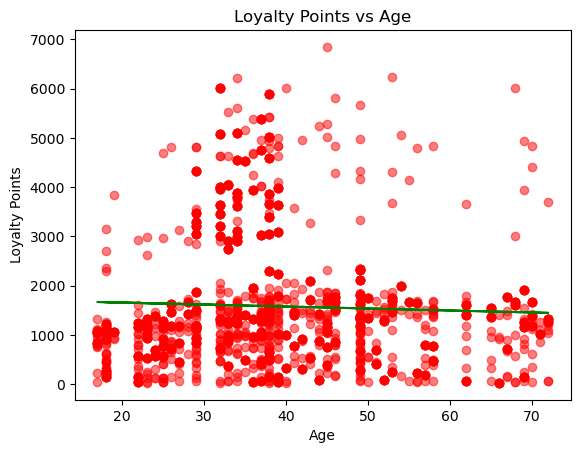

In [27]:
# Plot the graph with a regression line.
plt.scatter(X_age, y, alpha=0.5, color ='red')
plt.plot(X_age, y_pred_age, color='green')
plt.xlabel('Age')
plt.ylabel('Loyalty Points')
plt.title('Loyalty Points vs Age')
plt.show()

- The scatter plot confirms the previous observations for the coefficient visually: points are scattered broadly across all loyalty point values at every age, with no visible upward or downward drift. The regression line is essentially flat. Age alone is not a useful predictor of loyalty points.

# Assignment activity 2: Exploring data with decision trees

In [29]:
# Import the CSV file you prepared in Module 1.
df2 = pd.read_csv('turtle_reviews_clean.csv')

# Sense-check.
df2.info()
df2.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   gender          2000 non-null   object 
 1   age             2000 non-null   int64  
 2   remuneration    2000 non-null   float64
 3   spending_score  2000 non-null   int64  
 4   loyalty_points  2000 non-null   int64  
 5   education       2000 non-null   object 
 6   product         2000 non-null   int64  
 7   review          2000 non-null   object 
 8   summary         2000 non-null   object 
dtypes: float64(1), int64(4), object(4)
memory usage: 140.8+ KB


,gender,age,remuneration,spending_score,loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap


In [31]:
# Specify the dependent variable (target).
y = df2['loyalty_points']

# Specify the independent variables — same three as Activity 1.
X = df2[['age', 'remuneration', 'spending_score']]

# Sense-check.
X.shape
X.head()

,age,remuneration,spending_score
0,18,12.30,39
1,23,12.30,81
2,22,13.12,6
3,25,13.12,77
4,33,13.94,40


## 2. Create, Train & Test DataSets

In [32]:
from sklearn.model_selection import train_test_split

# Split the data 70:30 (train:test).
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Sense-check the shapes.
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(1400, 3) (600, 3) (1400,) (600,)


## 3. Create Decision Tree Regressor

In [33]:
# Import the DecisionTreeRegressor class.
from sklearn.tree import DecisionTreeRegressor

# Create the regressor object.
regressor = DecisionTreeRegressor(random_state=42)

# Fit the regressor to the training data.
regressor.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [34]:
# Evaluate the Model

# Predict on training and test data.
y_train_pred = regressor.predict(X_train)
y_test_pred = regressor.predict(X_test)

# Import regression metrics.
from sklearn.metrics import mean_squared_error, r2_score

# Compare training vs test performance.
print('Training R-squared:', r2_score(y_train, y_train_pred))
print('Test R-squared:', r2_score(y_test, y_test_pred))
print('Training MSE:', mean_squared_error(y_train, y_train_pred))
print('Test MSE:', mean_squared_error(y_test, y_test_pred))

Training R-squared: 1.0
Test R-squared: 0.9960547369776616
Training MSE: 0.0
Test MSE: 6390.525


In [35]:
# Prune the Model

# Create a pruned regressor
regressor_pruned = DecisionTreeRegressor(random_state=42,
                                          max_depth=4,
                                          min_samples_leaf=5,
                                          min_samples_split=5)

# Fit the pruned regressor.
regressor_pruned.fit(X_train, y_train)

# Predict on training and test data.
y_train_pred_pruned = regressor_pruned.predict(X_train)
y_test_pred_pruned = regressor_pruned.predict(X_test)

# Compare performance after pruning.
print('Pruned Training R-squared:', r2_score(y_train, y_train_pred_pruned))
print('Pruned Test R-squared:', r2_score(y_test, y_test_pred_pruned))
print('Pruned Training MSE:', mean_squared_error(y_train, y_train_pred_pruned))
print('Pruned Test MSE:', mean_squared_error(y_test, y_test_pred_pruned))

Pruned Training R-squared: 0.9460890153610675
Pruned Test R-squared: 0.9433469740538758
Pruned Training MSE: 89324.90757172268
Pruned Test MSE: 91766.39848457077


## 4. Plot the model

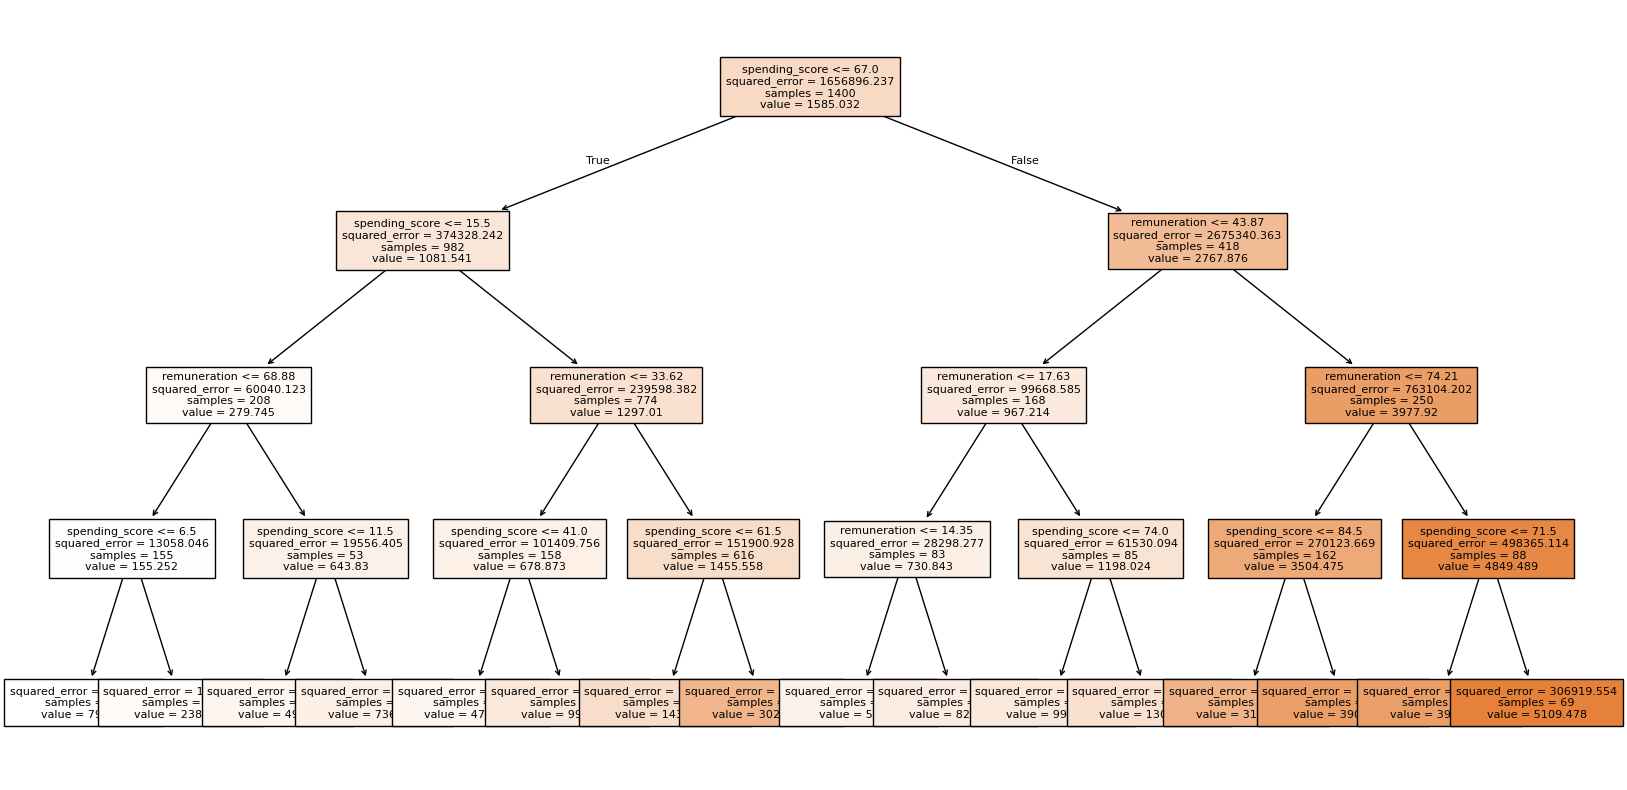

In [36]:
from sklearn import tree

fig, ax = plt.subplots(figsize=(20, 10))
tree.plot_tree(regressor_pruned, feature_names=X.columns, filled=True, fontsize=8)
plt.show()

Before pruning, there was a noticeable gap between training and test R², which can be said to be the classic overfitting. After pruning, that gap essentially disappears: training R² = 0.946, test R² = 0.943. This tells us that the pruned tree isn't memorising the training data; it has found a genuine, reusable pattern that holds up on customers it's never seen before.

## How does this compare to the Linear regression in Activity 1

In Activity 1, the best single linear regression (spending score alone) only reached R² = 0.452, explaining less than half the variation in loyalty points. This decision tree explains 94%. This isn't a small improvement, but a completely different order of magnitude of explanatory power, and it shows something specific: the relationship between these variables and loyalty points isn't a simple straight line; rather, it depends on combinations of variables together. A linear model can only ever say "loyalty points go up by X for every unit increase in spending," treated in isolation. This tree says "loyalty points behave completely differently depending on which customer segment you're in", which is a much closer match to how real customer behaviour actually works.

## Insights & Observations 

- The very first (root) split is on spending_score <= 67.0. In a decision tree, whichever variable gets used at the root is the one that, on its own, best separates high and low outcomes across the whole dataset. This confirms what Activity 1 already hinted at: spending score is the single strongest driver of loyalty points among the three variables tested.

- remuneration appears as the second-level split in every branch of the tree. Once customers are grouped by spending level, remuneration is what further separates high-loyalty from low-loyalty customers within that group. This is a genuinely richer insight than Activity 1 offers: remuneration matters, but conditionally, its effect depends on what spending band the customer is already in.

- age does not appear anywhere in the tree, at any split. Given complete freedom to choose the most useful variable at every single decision point, the algorithm never once chose age. That's strong, model-based confirmation of Activity 1's near-zero R² finding for age. Two independent methods now agree age is not a useful lever for predicting or influencing loyalty points.

- The highest-value leaf (5,109 average loyalty points, from 69 customers) sits in the branch where spending_score > 67 AND remuneration > 74.21. The lowest-value leaf (155 average loyalty points) sits where spending_score ≤ 15.5 AND remuneration ≤ 68.88 AND spending_score ≤ 6.5. Simply put, customers who are both high spenders and high earners accumulate dramatically more loyalty points than customers who are low spenders regardless of income and the gap between these two groups is big.

### How the business can use this directly: 

Rather than a single loyalty-points formula, marketing now has clear, actionable customer segments defined by two variables, which are "high spend + high income" as the priority retention/upsell segment, versus "low spend" customers (regardless of income) as a re-engagement target, since spending score is consistently the dominant factor before income comes into play at all.

# Assignment Activity 3: Making predictions with clustering

In [37]:
# Import necessary libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import accuracy_score
from scipy.spatial.distance import cdist

import warnings
warnings.filterwarnings('ignore')


# Load the CSV file(s) as df2.
df2 = pd.read_csv('turtle_reviews_clean.csv')

# View DataFrame.
df2.head()

,gender,age,remuneration,spending_score,loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap


In [38]:
# Drop unnecessary columns — keep only remuneration and spending_score.
df3 = df2[['remuneration', 'spending_score']]

# View DataFrame.
df3.head()

,remuneration,spending_score
0,12.30,39
1,12.30,81
2,13.12,6
3,13.12,77
4,13.94,40


In [39]:
# Explore the data.
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   remuneration    2000 non-null   float64
 1   spending_score  2000 non-null   int64  
dtypes: float64(1), int64(1)
memory usage: 31.4 KB


In [40]:
# Descriptive statistics.
df3.describe()

,remuneration,spending_score
count,2000.000000,2000.000000
mean,48.079060,50.000000
std,23.123984,26.094702
min,12.300000,1.000000
25%,30.340000,32.000000
50%,47.150000,50.000000
75%,63.960000,73.000000
max,112.340000,99.000000


## 2. Plot

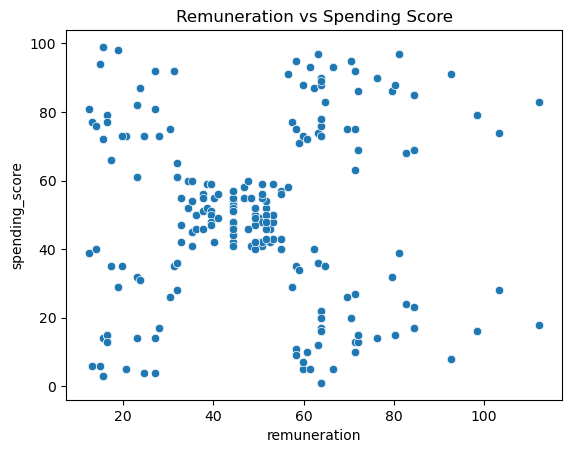

In [41]:
# Create a scatterplot with Seaborn.
sns.scatterplot(x='remuneration', y='spending_score', data=df3)
plt.title('Remuneration vs Spending Score')
plt.show()

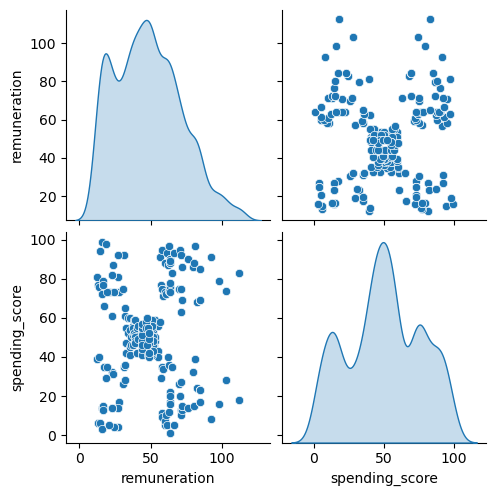

In [42]:
# Create a pairplot with Seaborn.
sns.pairplot(df3, diag_kind='kde')
plt.show()

## 3. Elbow and silhoutte methods

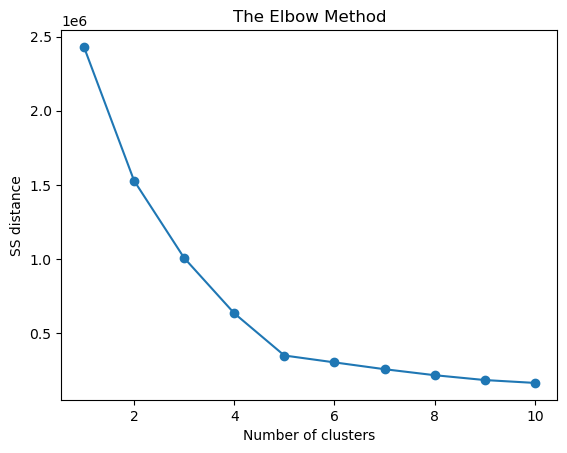

In [43]:
# Determine the number of clusters: Elbow method.
ss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i,
                    init='k-means++',
                    max_iter=300,
                    n_init=10,
                    random_state=42)
    kmeans.fit(df3)
    ss.append(kmeans.inertia_)

# Plot the elbow method.
plt.plot(range(1, 11), ss, marker='o')
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('SS distance')
plt.show()

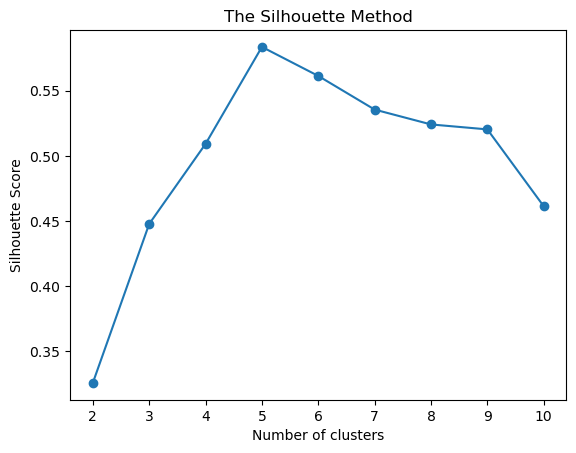

In [44]:
# Determine the number of clusters: Silhouette method.
sil = []
kmax = 10

for k in range(2, kmax + 1):
    kmeans_s = KMeans(n_clusters=k, random_state=42).fit(df3)
    labels = kmeans_s.labels_
    sil.append(silhouette_score(df3, labels, metric='euclidean'))

# Plot the silhouette method.
plt.plot(range(2, kmax + 1), sil, marker='o')
plt.title('The Silhouette Method')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score')
plt.show()

**Determining the number of clusters:**

The Elbow method shows SS distance dropping sharply from k=1 to k=4, then the curve visibly flattens from k=5 onwards. Each additional cluster beyond this point produces only a small further reduction. This flattening point marks the "elbow," and it falls at k=5.

The Silhouette method confirms this independently: the score rises sharply and peaks clearly at k=5 (approximately 0.58), then declines for every value of k beyond it. Unlike the elbow, which requires some visual judgement about where the bend is, the silhouette method gives an unambiguous single maximum, and it lands on exactly the same value as the elbow method's bend.

Because both independent methods agree precisely on k=5, this is a well-supported choice for the number of clusters, with considerably more confidence than either method would give alone.

## 4. Evaluate k-means model at different values of k

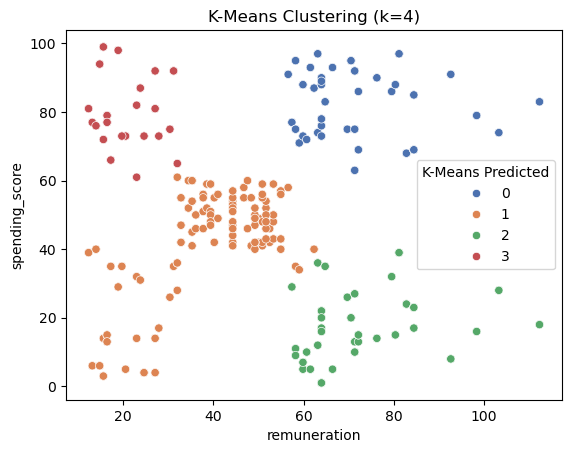

In [45]:
# k=4
kmeans4 = KMeans(n_clusters=4, max_iter=15000, 
                 init='k-means++', random_state=42).fit(df3[['remuneration',
                                                             'spending_score']])
df3['K-Means Predicted'] = kmeans4.labels_

sns.scatterplot(x='remuneration', y='spending_score',
                data=df3, hue='K-Means Predicted', palette='deep')
plt.title('K-Means Clustering (k=4)')
plt.show()

Four groups are visible: a low-remuneration/high-spend group (red, top-left), a low-remuneration/low-spend group merged together with the central-middle group (orange, occupying a large central-to-left blob), a high-remuneration/low-spend group (green, bottom-right), and a high-remuneration/high-spend group (blue, top-right). The orange group is doing double duty here as it's covering two visually distinct areas (the low-spend cluster on the left and the dense central cluster) that don't obviously belong together. That's a sign this k is too coarse as genuinely different customer types are being forced into one label.

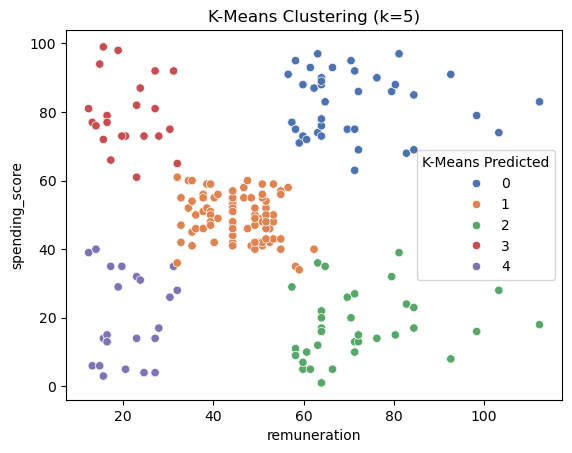

In [46]:
# k=5
kmeans5 = KMeans(n_clusters=5, max_iter=15000, 
                 init='k-means++', random_state=42).fit(df3[['remuneration', 'spending_score']])
df3['K-Means Predicted'] = kmeans5.labels_

sns.scatterplot(x='remuneration', y='spending_score', 
                data=df3, hue='K-Means Predicted', palette='deep')
plt.title('K-Means Clustering (k=5)')
plt.show()

This plot is visibly much cleaner. There are five distinct blobs with gaps between them: high remuneration + high spend (blue, top-right), high remuneration + low spend (green, bottom-right), low remuneration + high spend (red, top-left), low remuneration + low spend (purple, bottom-left), and a distinct middle-income/middle-spend cluster sitting in the centre (orange). Every group now occupies its own clearly bounded region with visible white space between clusters.

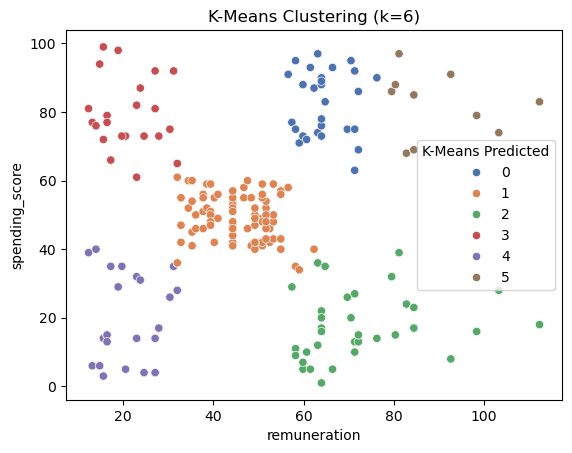

In [47]:
# k=6
kmeans6 = KMeans(n_clusters=6, max_iter=15000, 
                 init='k-means++', random_state=42).fit(df3[['remuneration', 'spending_score']])
df3['K-Means Predicted'] = kmeans6.labels_

sns.scatterplot(x='remuneration', y='spending_score', 
                data=df3, hue='K-Means Predicted', palette='deep')
plt.title('K-Means Clustering (k=6)')
plt.show()

The five groups from k=5 are still here, but the high-remuneration/high-spend group (previously all blue) has been split into two colours (blue and brown) with no visible gap between them, as they occupy the same continuous region of the plot. This is an over-fragmentation flag: k=6 isn't finding a genuinely new customer type, it's just arbitrarily cutting one real group in half.

### Explanation of which gives the best clustering

Comparing k=4, k=5, and k=6 confirms that k=5 produces the best clustering. At k=4, two genuinely distinct customer types (low-remuneration/low-spend customers and the middle-income/middle-spend customers) are incorrectly merged into a single group, losing meaningful distinction between them. At k=6, the high-remuneration/high-spend group is split into two sub-groups with no visible separation between them, indicating over-fragmentation rather than genuine structure. 

At k=5, all five groups occupy clearly bounded regions of the plot with visible gaps between them, and the resulting groups form five sensible, business-interpretable segments defined by combinations of remuneration and spending behaviour. This visual evidence, combined with the Elbow and Silhouette methods both independently pointing to k=5, confirms k=5 as the optimal number of clusters.

## 5. Fit final model and justify your choice

In [48]:
# Apply the final model.
kmeans_final = KMeans(n_clusters=5, max_iter=15000, init='k-means++', 
                      random_state=42).fit(df3[['remuneration', 'spending_score']])
df3['K-Means Predicted'] = kmeans_final.labels_

# Check the number of observations per predicted class.
df3['K-Means Predicted'].value_counts()

K-Means Predicted
1    774
0    356
2    330
4    271
3    269
Name: count, dtype: int64

k=5 was selected based on the result between both the Elbow method (visible flattening point at k=5) and the Silhouette method (clear peak score at k=5), providing stronger evidence than either method alone. Comparison against k=4 and k=6 in the previous step further confirmed that k=5 produces the most visually distinct, well-separated clusters without merging different groups or splitting a unified group.

## 6. Plot and interpret the clusters

In [51]:
# View the DataFrame.
df3.head()

,remuneration,spending_score,K-Means Predicted
0,12.30,39,4
1,12.30,81,3
2,13.12,6,4
3,13.12,77,3
4,13.94,40,4


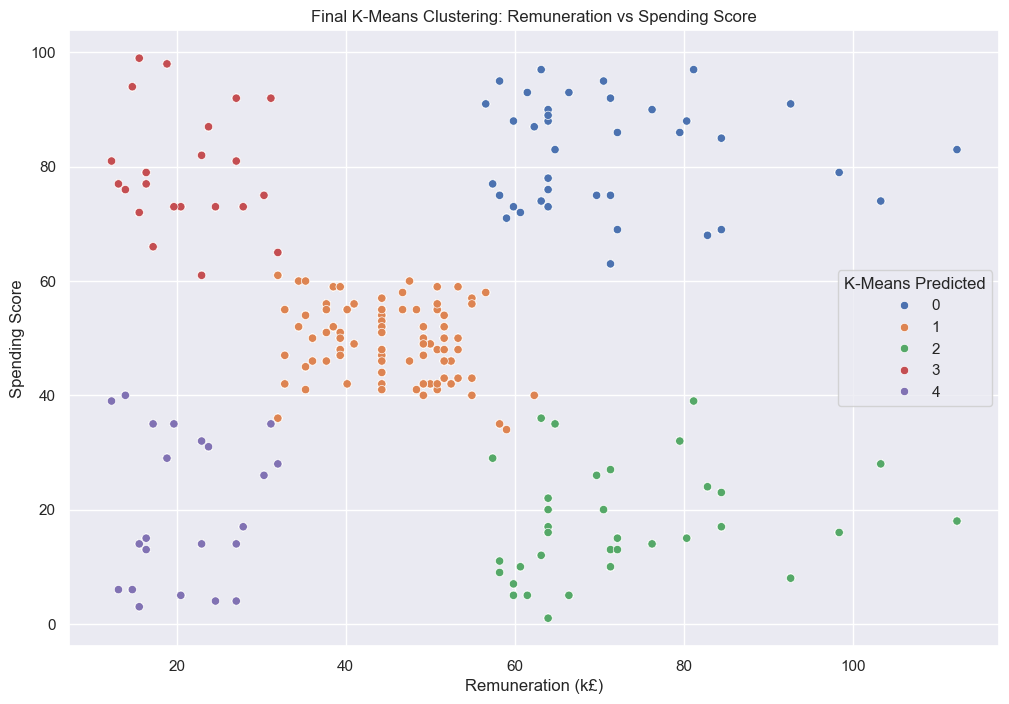

In [52]:
# Visualising the clusters.
sns.set(rc={'figure.figsize': (12, 8)})

sns.scatterplot(x='remuneration', y='spending_score', data=df3, hue='K-Means Predicted', palette='deep')
plt.title('Final K-Means Clustering: Remuneration vs Spending Score')
plt.xlabel('Remuneration (k£)')
plt.ylabel('Spending Score')
plt.show()

## Describing the groups

The final k=5 clustering reveals five clearly distinct customer segments, defined by combinations of remuneration and spending score:

- **Cluster 0 — High Remuneration, High Spend** (top-right): customers earning roughly £60k–£115k with spending scores of 60–100. These are Turtle Games' most valuable customers: high earning power combined with high willingness to spend.

- **Cluster 1 — Mid Remuneration, Mid Spend** (centre): customers earning roughly £35k–£60k with spending scores of 40–60. This is the largest and most "average" segment: moderate earners with moderate, unremarkable spending behaviour.

- **Cluster 2 — High Remuneration, Low Spend** (bottom-right): customers earning roughly £60k–£115k but with spending scores under 40. These customers can afford to spend more but are not currently doing so.

- **Cluster 3 — Low Remuneration, High Spend** (top-left): customers earning roughly £10k–£30k but with spending scores of 60–100. These customers spend well beyond what their income level would typically suggest.

- **Cluster 4 — Low Remuneration, Low Spend** (bottom-left): customers earning roughly £10k–£30k with spending scores under 40. Lower earning power paired with correspondingly low spending: the most price-sensitive, lowest-value segment.

## Insights & Observation

The five clusters are not evenly balanced. Cluster 1 (774 customers) is substantially larger than the others, accounting for nearly 39% of the entire customer base, while the remaining four clusters (0, 2, 3, 4) are much closer to each other in size, ranging from 269 to 356 customers each (roughly 13–18% of the base).

This imbalance makes sense given the scatter plot: cluster 1 corresponds to the dense central group (middle remuneration, middle spending score), where most "average" customers naturally sit, while the other four clusters sit further out at the corners of the plot (the high/low combinations of remuneration and spending), which are naturally smaller, more distinct segments. This reflects a real characteristic of the customer base: most customers behave "typically," while the four corner segments represent smaller but more clearly differentiated groups that are likely to be the more actionable ones for targeted marketing, since they represent more extreme, well-defined behaviour rather than the average middle ground.

## Suggested actions per group

- **Cluster 0 (High Remuneration, High Spend):** Turtle Games' premium segment. Priority target for loyalty rewards, early access to new products, and premium/exclusive offerings; protecting and retaining this group should be the top priority, as they combine high value with proven willingness to spend.

- **Cluster 2 (High Remuneration, Low Spend):** the clearest untapped growth opportunity. These customers have the financial capacity to spend more but currently don't. Marketing should investigate why through targeted surveys, personalised recommendations, or incentives (e.g. first-purchase discounts on higher-value items) designed specifically to convert latent spending power into actual purchases.

- **Cluster 3 (Low Remuneration, High Spend):** highly engaged, price-insensitive customers despite limited income. These are likely enthusiast/hobbyist customers with strong brand loyalty. Suitable for loyalty programmes, community engagement, and affordable premium add-ons, but should not be targeted with high-price offers that exceed their financial capacity.

- **Cluster 4 (Low Remuneration, Low Spend):** the lowest-priority segment for premium marketing spend. Best served with budget-friendly product lines, entry-level offers, and value-based promotions rather than investment-heavy campaigns, since low income limits realistic upsell potential.

- **Cluster 1 (Mid Remuneration, Mid Spend):** the largest but least distinct segment. Rather than one-size-fits-all campaigns, this group is a candidate for further sub-segmentation such as incorporating loyalty points or product category data to uncover more actionable structure within it, since "average" behaviour on its own gives limited direction for targeted marketing.

# Assignment Activity 4: Analysing customer sentiments with reviews

In [5]:
!pip install wordcloud textblob nltk

import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

!python -m textblob.download_corpora

[nltk_data] Downloading package punkt to /Users/Bosola/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/Bosola/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/Bosola/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


[nltk_data] Downloading package brown to /Users/Bosola/nltk_data...
[nltk_data]   Unzipping corpora/brown.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/Bosola/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/Bosola/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /Users/Bosola/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package conll2000 to
[nltk_data]     /Users/Bosola/nltk_data...
[nltk_data]   Unzipping corpora/conll2000.zip.
[nltk_data] Downloading package movie_reviews to
[nltk_data]     /Users/Bosola/nltk_data...
[nltk_data]   Package movie_reviews is already up-to-date!
Finished.


In [6]:
# Import all the necessary packages.
import pandas as pd
import numpy as np
import nltk
import os
import matplotlib.pyplot as plt

from wordcloud import WordCloud
from nltk.tokenize import word_tokenize
from nltk.probability import FreqDist
from nltk.corpus import stopwords
from textblob import TextBlob
from scipy.stats import norm

from collections import Counter

import warnings
warnings.filterwarnings('ignore')

In [9]:
# Load the data set as df3.
df4 = pd.read_csv('turtle_reviews_clean.csv')

# View DataFrame.
df4.head()

,gender,age,remuneration,spending_score,loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap


In [11]:
# Explore data set.
df4.info()
df4.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   gender          2000 non-null   object 
 1   age             2000 non-null   int64  
 2   remuneration    2000 non-null   float64
 3   spending_score  2000 non-null   int64  
 4   loyalty_points  2000 non-null   int64  
 5   education       2000 non-null   object 
 6   product         2000 non-null   int64  
 7   review          2000 non-null   object 
 8   summary         2000 non-null   object 
dtypes: float64(1), int64(4), object(4)
memory usage: 140.8+ KB


,age,remuneration,spending_score,loyalty_points,product
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,39.495000,48.079060,50.000000,1578.032000,4320.521500
std,13.573212,23.123984,26.094702,1283.239705,3148.938839
min,17.000000,12.300000,1.000000,25.000000,107.000000
25%,29.000000,30.340000,32.000000,772.000000,1589.250000
50%,38.000000,47.150000,50.000000,1276.000000,3624.000000
75%,49.000000,63.960000,73.000000,1751.250000,6654.000000
max,72.000000,112.340000,99.000000,6847.000000,11086.000000


In [12]:
# Keep necessary columns. Drop unnecessary columns.
df4 = df4[['review', 'summary']]

# View DataFrame.
df4.head()

,review,summary
0,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,As my review of GF9's previous screens these w...,Money trap


In [13]:
# Determine if there are any missing values.
df4.isna().sum()

review     0
summary    0
dtype: int64

# 2. Prepatre the Data for NLP

### 2a. Lower case and join

In [14]:
# Review: Change all to lower case and join with a space.
df4['review'] = df4['review'].str.lower()
df4['review'] = df4['review'].apply(lambda x: ' '.join(x.split()))

In [15]:
# Summary: Change all to lower case and join with a space.
df4['summary'] = df4['summary'].str.lower()
df4['summary'] = df4['summary'].apply(lambda x: ' '.join(x.split()))

### 2b. Replace punctuation

In [17]:
import re

# Replace all the punctuations in review column.
df4['review'] = df4['review'].apply(lambda x: re.sub(r'[^\w\s]', '', x))

# View output.
df4['review'].head()

0    When it comes to a DMs screen the space on the...
1    An Open Letter to GaleForce9\n\nYour unpainted...
2    Nice art nice printing  Why two panels are fil...
3    Amazing buy Bought it as a gift for our new dm...
4    As my review of GF9s previous screens these we...
Name: review, dtype: object

In [18]:
# Replace all the puncuations in summary column.
df4['summary'] = df4['summary'].apply(lambda x: re.sub(r'[^\w\s]', '', x))

# View output.
df4['summary'].head()

0    The fact that 50 of this space is wasted on ar...
1    Another worthless Dungeon Masters screen from ...
2                       pretty but also pretty useless
3                                           Five Stars
4                                           Money trap
Name: summary, dtype: object

### 2c. Drop duplicates

In [19]:
# Drop duplicates in both columns.
df4 = df4.drop_duplicates(subset=['review'])
df4 = df4.drop_duplicates(subset=['summary'])

# View DataFrame.
df4.shape

(1385, 2)

# 3. Tokenise and create wordclouds

In [20]:
# Create new DataFrame (copy DataFrame).
df5 = df4.copy()

# View DataFrame.
df5.head()

,review,summary
0,When it comes to a DMs screen the space on the...,The fact that 50 of this space is wasted on ar...
1,An Open Letter to GaleForce9\n\nYour unpainted...,Another worthless Dungeon Masters screen from ...
2,Nice art nice printing Why two panels are fil...,pretty but also pretty useless
3,Amazing buy Bought it as a gift for our new dm...,Five Stars
4,As my review of GF9s previous screens these we...,Money trap


In [21]:
# Apply tokenisation to both columns.
df5['review_tokens'] = df5['review'].apply(word_tokenize)
df5['summary_tokens'] = df5['summary'].apply(word_tokenize)

# View DataFrame.
df5.head()

,review,summary,review_tokens,summary_tokens
0,When it comes to a DMs screen the space on the...,The fact that 50 of this space is wasted on ar...,"[When, it, comes, to, a, DMs, screen, the, spa...","[The, fact, that, 50, of, this, space, is, was..."
1,An Open Letter to GaleForce9\n\nYour unpainted...,Another worthless Dungeon Masters screen from ...,"[An, Open, Letter, to, GaleForce9, Your, unpai...","[Another, worthless, Dungeon, Masters, screen,..."
2,Nice art nice printing Why two panels are fil...,pretty but also pretty useless,"[Nice, art, nice, printing, Why, two, panels, ...","[pretty, but, also, pretty, useless]"
3,Amazing buy Bought it as a gift for our new dm...,Five Stars,"[Amazing, buy, Bought, it, as, a, gift, for, o...","[Five, Stars]"
4,As my review of GF9s previous screens these we...,Money trap,"[As, my, review, of, GF9s, previous, screens, ...","[Money, trap]"


In [22]:
# Review: Create a word cloud.
review_text = ' '.join(df5['review'])
review_wordcloud = WordCloud(width=800, height=400, background_color='white').generate(review_text)

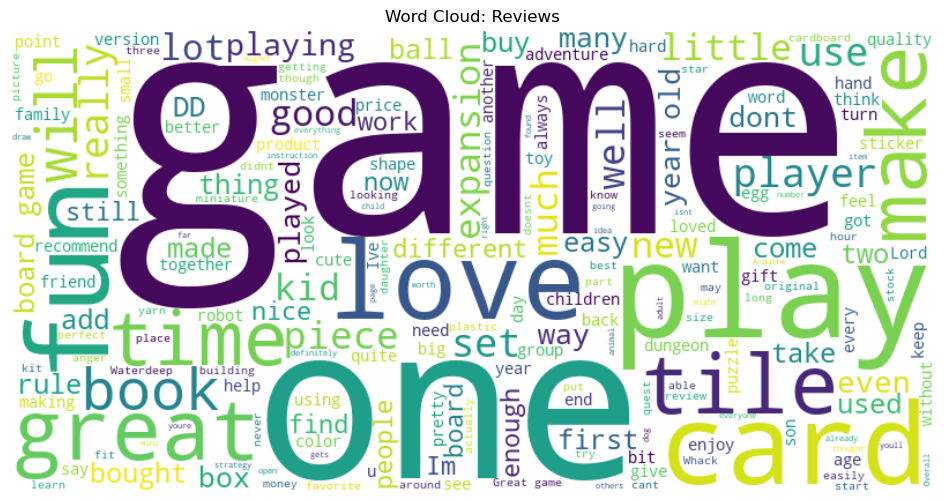

In [23]:
# Review: Plot the WordCloud image.
plt.figure(figsize=(12, 6))
plt.imshow(review_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud: Reviews')
plt.show()

In [24]:
# Summary: Create a word cloud.
summary_text = ' '.join(df5['summary'])
summary_wordcloud = WordCloud(width=800, height=400, background_color='white').generate(summary_text)

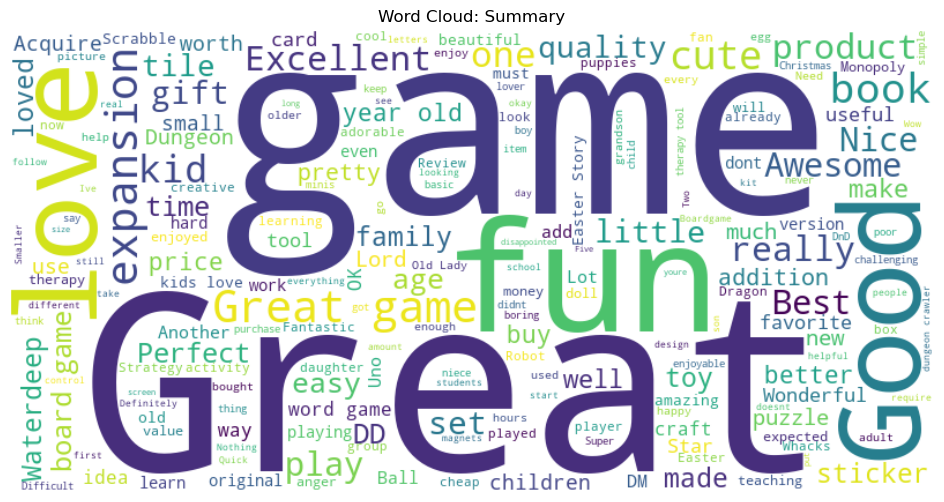

In [25]:
# Summary: Plot the WordCloud image.
plt.figure(figsize=(12, 6))
plt.imshow(summary_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud: Summary')
plt.show()

# 4. Frequency distribution and polarity

### 4a. Create frequency distribution

In [26]:
# Determine the frequency distribution.
all_review_words = [word for tokens in df5['review_tokens'] for word in tokens]
freq_dist_review = FreqDist(all_review_words)
freq_dist_review.most_common(15)

[('the', 4309),
 ('and', 2923),
 ('to', 2890),
 ('a', 2786),
 ('of', 2289),
 ('I', 1886),
 ('is', 1604),
 ('it', 1585),
 ('game', 1356),
 ('for', 1340),
 ('this', 1205),
 ('with', 1131),
 ('in', 1025),
 ('you', 990),
 ('that', 970)]

### 4b. Remove alphanumeric characters and stopwords

In [27]:
# Delete all the alpanum.
alpha_words = [word for word in all_review_words if word.isalpha()]

# Remove all the stopwords
stop_words = set(stopwords.words('english'))
filtered_words = [word for word in alpha_words if word not in stop_words]

### 4c. Create wordcloud without stopwords

In [28]:
# Create a wordcloud without stop words.
filtered_text = ' '.join(filtered_words)
wordcloud_clean = WordCloud(width=800, height=400, background_color='white').generate(filtered_text)

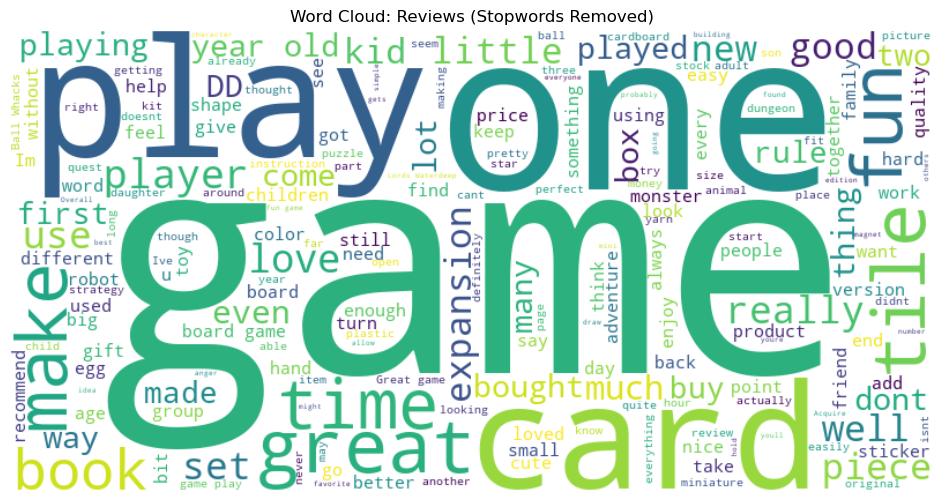

In [29]:
# Plot the wordcloud image.
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud_clean, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud: Reviews (Stopwords Removed)')
plt.show()

### 4d. Identify 15 most common words and polarity

In [30]:
# Determine the 15 most common words.
freq_dist_clean = FreqDist(filtered_words)
most_common_15 = freq_dist_clean.most_common(15)
most_common_15

[('I', 1886),
 ('game', 1356),
 ('The', 777),
 ('play', 446),
 ('one', 439),
 ('fun', 389),
 ('This', 378),
 ('like', 370),
 ('get', 293),
 ('great', 286),
 ('It', 279),
 ('cards', 271),
 ('tiles', 266),
 ('really', 259),
 ('My', 255)]

In [31]:
# Calculate sentiment polarity of each of these words.
word_polarity = [(word, count, TextBlob(word).sentiment.polarity) for word, count in most_common_15]
word_polarity

[('I', 1886, 0.0),
 ('game', 1356, -0.4),
 ('The', 777, 0.0),
 ('play', 446, 0.0),
 ('one', 439, 0.0),
 ('fun', 389, 0.3),
 ('This', 378, 0.0),
 ('like', 370, 0.0),
 ('get', 293, 0.0),
 ('great', 286, 0.8),
 ('It', 279, 0.0),
 ('cards', 271, 0.0),
 ('tiles', 266, 0.0),
 ('really', 259, 0.2),
 ('My', 255, 0.0)]

# 5. Review polarity and sentiment

In [32]:
# Provided function.
def generate_polarity(comment):
    '''Extract polarity score (-1 to +1) for each comment'''
    return TextBlob(comment).sentiment[0]

In [36]:
# Determine polarity of both columns.
df5['review_polarity'] = df5['review'].apply(generate_polarity)
df5['summary_polarity'] = df5['summary'].apply(generate_polarity)

# View output.
df5.head()

,review,summary,review_tokens,summary_tokens,review_polarity,summary_polarity
0,When it comes to a DMs screen the space on the...,The fact that 50 of this space is wasted on ar...,"[When, it, comes, to, a, DMs, screen, the, spa...","[The, fact, that, 50, of, this, space, is, was...",-0.036111,0.15
1,An Open Letter to GaleForce9\n\nYour unpainted...,Another worthless Dungeon Masters screen from ...,"[An, Open, Letter, to, GaleForce9, Your, unpai...","[Another, worthless, Dungeon, Masters, screen,...",0.035952,-0.80
2,Nice art nice printing Why two panels are fil...,pretty but also pretty useless,"[Nice, art, nice, printing, Why, two, panels, ...","[pretty, but, also, pretty, useless]",0.116640,0.00
3,Amazing buy Bought it as a gift for our new dm...,Five Stars,"[Amazing, buy, Bought, it, as, a, gift, for, o...","[Five, Stars]",0.578788,0.00
4,As my review of GF9s previous screens these we...,Money trap,"[As, my, review, of, GF9s, previous, screens, ...","[Money, trap]",-0.316667,0.00


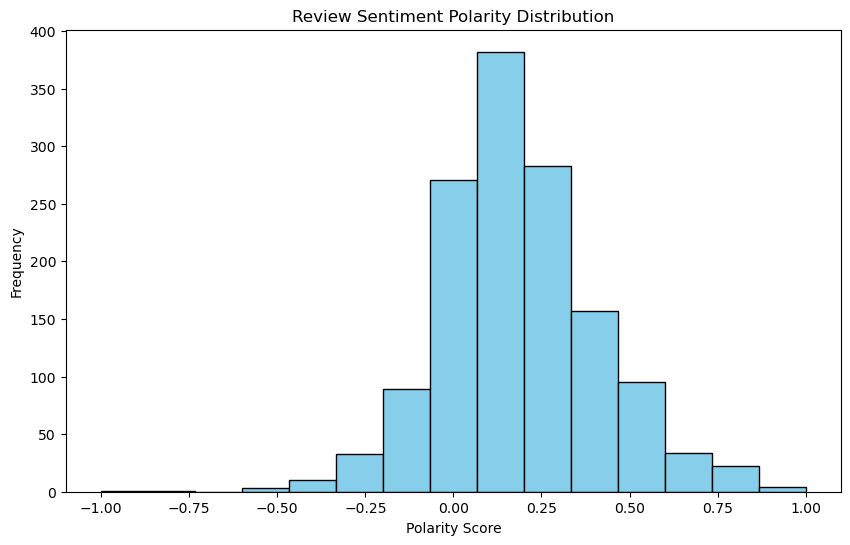

In [38]:
# Review: Create a histogram plot with bins = 15.
# Histogram of polarity / sentiment score
plt.figure(figsize=(10, 6))
plt.hist(df5['review_polarity'], bins=15, color='skyblue', edgecolor='black')
plt.title('Review Sentiment Polarity Distribution')
plt.xlabel('Polarity Score')
plt.ylabel('Frequency')
plt.show()

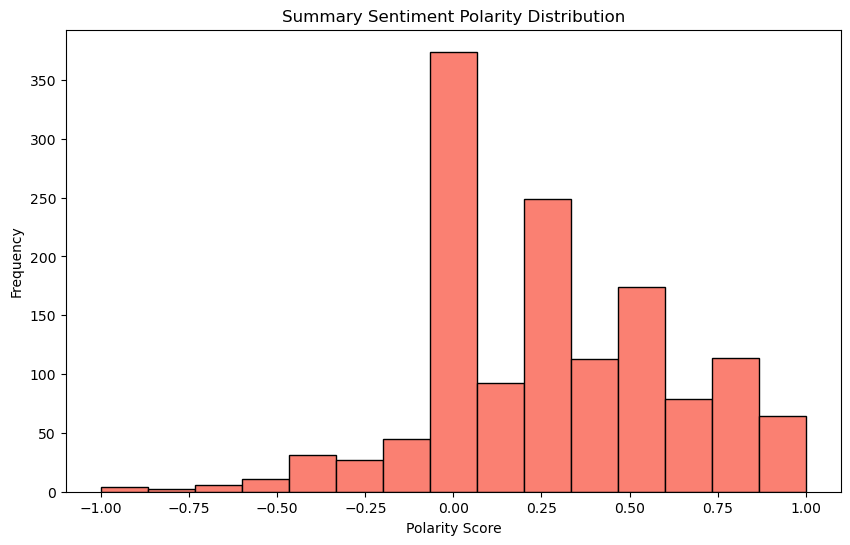

In [39]:
# Summary: Create a histogram plot with bins = 15.
# Histogram of polarity / sentiment score
plt.figure(figsize=(10, 6))
plt.hist(df5['summary_polarity'], bins=15, color='salmon', edgecolor='black')
plt.title('Summary Sentiment Polarity Distribution')
plt.xlabel('Polarity Score')
plt.ylabel('Frequency')
plt.show()

In [40]:
# Review the subjectivity

# Function to extract subjectivity.
def generate_subjectivity(comment):
    '''Extract subjectivity score (0 to 1) for each comment'''
    return TextBlob(comment).sentiment[1]

# Determine subjectivity of both columns.
df5['review_subjectivity'] = df5['review'].apply(generate_subjectivity)
df5['summary_subjectivity'] = df5['summary'].apply(generate_subjectivity)

# Review the subjectivity scores.
df5[['review_subjectivity', 'summary_subjectivity']].describe()

,review_subjectivity,summary_subjectivity
count,1385.000000,1385.000000
mean,0.512335,0.486119
std,0.161950,0.311496
min,0.000000,0.000000
25%,0.432231,0.200000
50%,0.500833,0.520000
75%,0.595833,0.750000
max,1.000000,1.000000


# 6. Identify top 20 positive and negative reviews and summaries respectively

In [41]:
# Top 20 negative reviews.
df5.sort_values('review_polarity', ascending=True).head(20)[['review', 'review_polarity']]

,review,review_polarity
208,BOOO UNLES YOU ARE PATIENT KNOW HOW TO MEASUR...,-1.000000
182,Incomplete kit Very disappointing,-0.780000
364,One of my staff will be using this game soon s...,-0.550000
117,I bought this as a Christmas gift for my grand...,-0.500000
174,I sent this product to my granddaughter The po...,-0.491667
347,My 8 yearold granddaughter and I were very fru...,-0.446250
538,I purchased this on the recommendation of two ...,-0.440741
989,If you like me used to play DD but now you and...,-0.400000
497,My son loves playing this game It was recommen...,-0.400000
1446,You can play the expansions one at a time or a...,-0.400000


In [42]:
# Top 20 negative summaries.
df5.sort_values('summary_polarity', ascending=True).head(20)[['summary', 'summary_polarity']]

,summary,summary_polarity
829,Boring,-1.000000
21,The worst value Ive ever seen,-1.000000
208,BORING UNLESS YOU ARE A CRAFT PERSON WHICH I AM,-1.000000
1166,before this I hated running any RPG campaign d...,-0.900000
1,Another worthless Dungeon Masters screen from ...,-0.800000
144,Disappointed,-0.750000
363,Promotes anger instead of teaching calming met...,-0.700000
890,Bad QualityAll made of paper,-0.700000
885,Too bad this is not what I was expecting,-0.700000
178,At age 31 I found these very difficult to make,-0.650000


In [43]:
# Top 20 positive reviews.
df5.sort_values('review_polarity', ascending=False).head(20)[['review', 'review_polarity']]

,review,review_polarity
790,Perfect,1.000000
1550,My daughter loves her stickers Awesome seller ...,1.000000
1967,Perfect for tutoring my grandson in spelling,1.000000
1245,The best part I see is the box What a wonderf...,0.880000
703,Great quality very cute and perfect for my to...,0.816667
1966,This is a great tool to have at hand when play...,0.800000
1150,Great price arrived on time with no damage Wil...,0.800000
36,The pictures are great Ive done one and gave ...,0.800000
1854,Prompt service and a great product,0.800000
1536,My granddaughter loves these So happy to find...,0.800000


In [44]:
# Top 20 positive summaries.
df5.sort_values('summary_polarity', ascending=False).head(20)[['summary', 'summary_polarity']]

,summary,summary_polarity
548,Excellent Therapy Tool,1.0
870,One of the best,1.0
140,Awesome sticker activity for the price,1.0
1508,Wonderful gift,1.0
863,one of the best games,1.0
134,Perfect for Preschooler,1.0
1094,Excellent product and everything I wanted it t...,1.0
543,EXCELLENT,1.0
1083,Best Dungeon Crawler,1.0
1488,The Perfect Gift for PreSchool Construction Fans,1.0


# 7. Insights and observations

- Dropping duplicates reduced the dataset from 2,000 rows to 1,385. This showed that nearly a third of "reviews" in this dataset were either exact duplicates or generic boilerplate text. This demonstrates why marketing's concern about data quality is well-founded, and why genuine textual insight requires this kind of cleaning before any analysis is trustworthy.

- The raw word clouds, created before stopword removal, were dominated visually by filler words ("the", "and", "to", "a"), carrying no real topic informatio. This further explains that word clouds are only useful once the text has been properly cleaned. The cleaned word cloud (stopwords removed) showed much more meaningful terms, with "game", "play", "fun", "cards", and "tiles" prominent, giving an immediate visual sense that customers talk mostly about gameplay experience and physical product components.

- The review polarity histogram and summary polarity histogram both show a distribution concentrated around a mildly positive centre, with most scores clustering close to zero and extending further into positive territory than negative. This is consistent with the sample top 20 positive reviews reaching polarity of 1.0, versus top 20 negative reviews bottoming out around -0.3 to -1.0 but with fewer extreme cases overall.

- The top 20 negative reviews and summaries reveal recurring, specific, actionable complaints: incomplete kits ("Incomplete kit, Very disappointing"), poor build quality ("Bad Quality, All made of paper"), and product confusion for the intended age group ("Confusing instructions and its not for 6 year..."). Several of the most negative-scoring entries relate to the same product theme (anger-management/RPG-related games being described as "boring" or inappropriate), suggesting a specific product line may need closer quality review.

The top 20 positive reviews and summaries are mostly gift-purchase and craft/hobby related ("Perfect for tutoring my grandson in spelling", "My granddaughter loves these"), suggesting a strong emotional, gift-giving use case driving the most enthusiastic reviews which is a theme marketing could lean into directly in campaign messaging.